# Introduction

The Women's Super League (WSL) in England is often considered to be of a higher caliber than the National Women's Soccer League (NWSL) in the United States, and I was interested in exploring whether the data reflects that sentiment. The Anatomy of a Goal compares shot locations, shot characteristics, and goal-scoring efficiency across the two leagues. Through these visualizations, I sought to understand how the leagues differ in the ways teams create and convert scoring opportunities.

**Link to the dashboard:** https://womens-soccer-analysis.onrender.com/

**Note:** This dashboard is hosted using Render's free tier, which automatically shuts down the web service after a period of inactivity. As a result, the dashboard may take a minute or longer to load upon initial access. Once the service is running, the dashboard should respond normally.

**Screenshot of Dashboard**

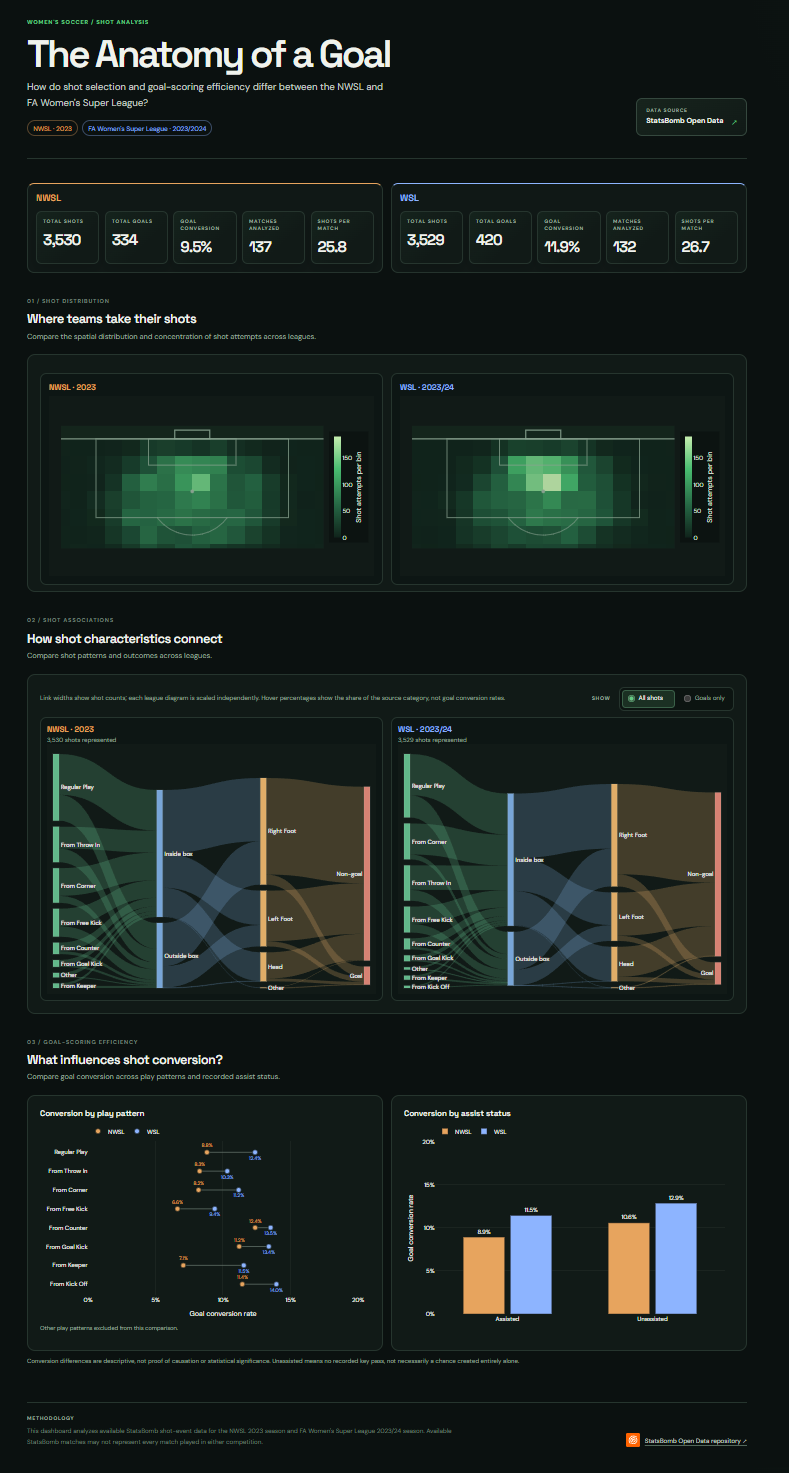

# Library Choice

## Library Overview

I used Plotly to create my visualizations and Dash to combine them into an interactive dashboard. Both libraries were created by Plotly and are open-source under the MIT license.

Plotly is primarily declarative, meaning that I can specify what I want a visualization to look like without having to write the code that draws each element. Similarly, Dash allows me to assemble the visualizations into an interactive dashboard with buttons, drop downs, etc.

Both libraries can be installed using pip:

`pip install plotly dash`

## Jupyter Integration and Limitations

Both Plotly and Dash can be used within Jupyter notebooks. This is particularly helpful when exploring data and experimenting with different visualizations.

One limitation I ran into with Dash was how to share my dashboard with others. I was able to run and interact with it on my own computer, but I needed to find a way for others to access it. I ended up using Render to host my dashboard, which required some additional setup. While I was able to host it for free, it can take a minute or longer to load if it hasn't been accessed recently.

## Why Plotly and Dash?

I knew I wanted to explore goal data, which I imagined is heavily influenced by shot location. I wanted a library that would display this spatial data on a soccer field in an aesthetically pleasing way. Additionally, I was curious about which body parts led to the most goals and how that might differ between leagues, which lends itself to a Sankey diagram. Dash allowed me to create and configure those complex diagrams in ways that made the data easy to interpret.

I also considered using Streamlit because it seemed easier to get started with and required less code to create a basic dashboard. However, I wanted more control over the look and feel of my dashboard, especially how the visualizations were styled and arranged. I ultimately chose to use Plotly and Dash because they offered more flexibility in customizing the dashboard and creating the visual experience I wanted.

# Data

## Overview
I used [StatsBomb Open Data](https://github.com/statsbomb/open-data) to create a dataset of 7,059 shots from the 2023 NWSL and 2023/2024 WSL seasons. StatsBomb's license allows for public sharing of analysis but prohibits redistribution of the underlying data and commercial use. It also requires the StatsBomb logo to be included in published analyses.

To create a dataframe of the shots, I filtered each event dataframe from each match table for both leagues on the following columns:

| Column | Column Description | Data Preparation |
|---|---|---|
| `id` | Unique identifier for the event | Selected |
| `location` | X and Y coordinates of the shot | Selected |
| `shot_outcome` | Outcome of the shot (e.g., goal, saved, blocked) | Selected |
| `shot_type` | Type of shot (e.g., open play, penalty) | Selected |
| `shot_body_part` | Body part used to take the shot | Selected |
| `play_pattern` | Pattern of play leading up to the shot | Selected |
| `match_id` | Unique identifier for the match | Selected |
| `team` | Team that took the shot | Selected |
| `player` | Player who took the shot | Selected |
| `shot_key_pass_id` | Identifier of the pass that led to the shot, if applicable | Selected |
| `competition_name` | Name of the competition | Added from competitions DataFrame |
| `season_name` | Season in which the match occurred | Added from competitions DataFrame |
| `assisted` | Boolean indicating whether the shot has an associated key pass | Calculated from `shot_key_pass_id` |
| `in_box` | Boolean indicating whether the shot was taken inside the penalty box | Calculated from `location` |

## Data Cleaning Process

### Data Exploration

In [ ]:
# Understand the data available in competitions
import pandas as pd
from statsbombpy import sb

competitions = sb.competitions()
competitions.head()

In [ ]:
# Determine which leagues were present

competitions[competitions["competition_gender"] == "female"]["competition_name"].unique()

In [ ]:
# Understand what data was available for those leagues
competitions[(competitions["competition_name"] == "FA Women's Super League") | (competitions["competition_name"] == "NWSL")][["competition_name","competition_id","season_id","season_name"]]

In [ ]:
# Understand what data was availabile within a specific league's season to determine what data I could use to compare leagues

nwsl_matches = sb.matches(competition_id=49, season_id=107)
nwsl_matches.head()

In [ ]:
# Understand what data was availabile within a specific league's match to determine what data I could use to compare teams
nwsl_events = sb.events(match_id=3881583).copy()
nwsl_events.columns

In [ ]:
# Filter on shots events to see if this is the data I need

nwsl_shots = nwsl_events[nwsl_events["type"] == "Shot"][["id","location","shot_outcome","shot_type","shot_body_part","play_pattern","match_id","team","player"]].copy()
nwsl_shots["competition_name"] = "NWSL"
nwsl_shots["season_name"] = "2023"
nwsl_shots.head()

In [ ]:
# Created a dataset of NWSL shots events for the 2023 season
def get_shots(match_id):
    nwsl_events = sb.events(match_id=match_id).copy()
    nwsl_shots = nwsl_events[nwsl_events["type"] == "Shot"][["id","location","shot_outcome","shot_type","shot_body_part","play_pattern","match_id","team","player"]].copy()
    nwsl_shots["competition_name"] = "NWSL"
    nwsl_shots["season_name"] = "2023"
    nwsl_shots["in_box"] = (nwsl_shots["location"].str[0] >=102) & (nwsl_shots["location"].str[1] >= 18) & (nwsl_shots["location"].str[1] <= 62)
    return nwsl_shots

all_nwsl_shots = pd.DataFrame()
for match_id in nwsl_matches["match_id"]:
    shot_data = get_shots(match_id)
    all_nwsl_shots = pd.concat([all_nwsl_shots, shot_data], ignore_index=True)

all_nwsl_shots.head()

In [ ]:
# Checked the WSL data to see if it was in the same structure (it was)
# Matches were the same
wsl_matches = sb.matches(competition_id=37, season_id=281)
wsl_matches.head()

# Events were the same
wsl_events = sb.events(match_id=3913082)
wsl_events.columns

# Could get the same WSL data for the 2023 season
all_wsl_shots = pd.DataFrame()
for match_id in wsl_matches["match_id"]:
    shot_data = get_shots(match_id)
    all_wsl_shots = pd.concat([all_wsl_shots, shot_data], ignore_index=True)

all_wsl_shots.head()

# Later I realized I needed assist data based on a change in direction for my visualization, so I tested adding that to the WSL shot data.
shots = wsl_events[wsl_events["type"] == "Shot"].copy()

shots["assisted"] = shots["shot_key_pass_id"].notna()

shots.groupby("assisted").agg(
    shots=("id", "count"),
    goals=("shot_outcome", lambda x: (x == "Goal").sum())
)

### Creating the Official Dataframe

In [ ]:
# Created a generic function to get match data based on a specific competition and season
def get_shots(competition_id, season_id):
    """This function retrieves all shot events for a given competition and season from the StatsBomb API."""
    competitions = sb.competitions()
    matches = sb.matches(competition_id=competition_id, season_id=season_id)
    shots = pd.DataFrame()

    for match_id in matches["match_id"]:
        match_shots = sb.events(match_id=match_id).copy()
        match_shots = match_shots[match_shots["type"] == "Shot"][["id","location","shot_outcome","shot_type","shot_body_part","play_pattern","match_id","team","player","shot_key_pass_id"]].copy()
        shots = pd.concat([shots, match_shots], ignore_index=True)

    shots["competition_name"] = competitions.loc[
        (competitions["competition_id"] == competition_id) & 
        (competitions["season_id"] == season_id),
        "competition_name"].iloc[0]

    shots["season_name"] = competitions.loc[
        (competitions["competition_id"] == competition_id) &
        (competitions["season_id"] == season_id),
        "season_name"
        ].iloc[0]

    shots["assisted"] = shots["shot_key_pass_id"].notna()

    shots["in_box"] = (shots["location"].str[0] >=102) & (shots["location"].str[1] >= 18) & (shots["location"].str[1] <= 62)

    return shots

In [ ]:
# Create a DataFrame for all shots in the WSL 2023 season
wsl_shots = get_shots(37, 281)

# Create a DataFrame for all shots in the NWSL 2023 season
nwsl_shots = get_shots(49, 107)

In [ ]:
# Combine the NWSL and WSL shots into a single DataFrame
all_shots = pd.concat([nwsl_shots, wsl_shots], ignore_index=True)

# Save the combined shots DataFrame to a Parquet file for working with Plotly and Dash locally
all_shots.to_parquet("data/shots.parquet", index=False)

# Visualization Techniques

## Heatmap

I used a heatmap to visualize where shots were taken most frequently. The style of play between the WSL and NWSL is different, so I was curious to see how their shot locations compared or contrasted. I thought this was a great way to visualize this data because it's highly intuitive to see the concentration of shot locations on a soccer pitch image, as opposed to the heatmap being categorical where the y-axis labels might be "Inside the box", "Outside the box", "In the 6 yard line", etc. Heatmaps should not be used when precision of data is critical to understanding or interpreting it.

## Sankey Diagram

A lot can contribute to how goals are scored and I was curious how I could understand the relationship between the factors in an easy-to-read way. I learned about Sankey diagrams, which were able to show connections between play patterns, shot location, and shot type (left foot, right foot, headers, etc.). This organization of information could answer questions about whether a league took more shots during certain types of plays, in certain locations, or with certain body parts. The Sankey has a toggle to highlight "Goals only" because a majority of shots don't result in goals, so that data can take up a lot of visual space. I don't think any other diagram would have allowed the comparison across play pattern, location, and shot type as intuitively. Sankey diagrams shouldn't be used when there are too many categories (or too few) for reasonable visual inferences to be made. I think my graph was on the cusp of this, but I still found it legible and helpful.

## Dumbbell Chart

I learned about this chart in 522 and thought it was a helpful way to show the difference between two values along the same category. The dumbbell chart actually helped me arrive at including conversion by play pattern into the larger vizualiation. After I saw the Heatmap and Sankey Diagram, the leagues seemed more or less the same, but I couldn't understand why the WSL scored more goals on average. That led me to thinking about how I could use the dumbbell chart to compare the NWSL and WSL on the types of play patterns, so maybe I could learn about what the WSL is utilizing or doing that maybe the NWSL isn't. Dumbbell charts are less effective when comparing more than two values per category or when displaying a large number of categories.

## Grouped Bar Chart
I chose a grouped bar chart to display conversion by assist status because it was relatively straightforward data (2 categories and a percentange per team). I wanted to easily compare the values across the teams and a grouped bar chart is perfect for this side-by-side comparison. Grouped bar charts shouldn't be used when data needs to display trends over time or when there are a large number of categories or groups.


## Chart Coordination & Arrangement
The coordination and arrangement of the graphs evolved as I explored the data. I began with the KPI statistics to get an overall understanding of the data, which highlighted the similarity in the number of shots taken by both leagues and the disparity in the number of goals scored. I wanted to understand if there were differences in how teams in the WSL played that might explain their higher shot conversion rates.

I began by exploring shot locations. While the heatmaps show some differences, they don't suggest drastically different shot locations between the leagues. I then wondered if there were differences in other shot characteristics, such as play pattern or body part.

The Sankey diagram allowed me to explore connections between play pattern, shot location, body part, and outcome that would have been difficult to capture by visualizing these features independently. For example, knowing whether a header was scored from a corner kick or during regular play provides additional context about how scoring opportunities were created. The Sankey diagrams highlighted some differences between the leagues, such as the number of goals scored from headers.

I then wanted a more direct comparison of conversion rates by play pattern to see if one league was particularly effective at converting shots from certain patterns of play. The dumbbell chart revealed that the WSL had a higher conversion rate across all displayed play patterns. Lastly, I used a grouped bar chart to explore whether differences in assisted and unassisted shots might provide additional insight into the disparity in conversion rates.

The arrangement of the visualizations reflects the progression of my exploration, with each visualization helping me answer a question raised by the previous one.

# Building and Exploring

### 1. Building the Basic Components

I began by creating KPI cards to get a high-level understanding of the data. These included the number of matches, shots, goals, shots per match, and goal conversion rate for each league. This helped establish the direction of my exploration, as the two leagues had nearly identical numbers of shots but noticeably different conversion rates.

In [ ]:
# I created reusable KPI cards
def _metric_card(label, value, card_id):
    return html.Article(
        [
            html.P(label, className="metric-label"),
            html.P(value, id=card_id, className="metric-value"),
        ],
        className="metric-card",
    )

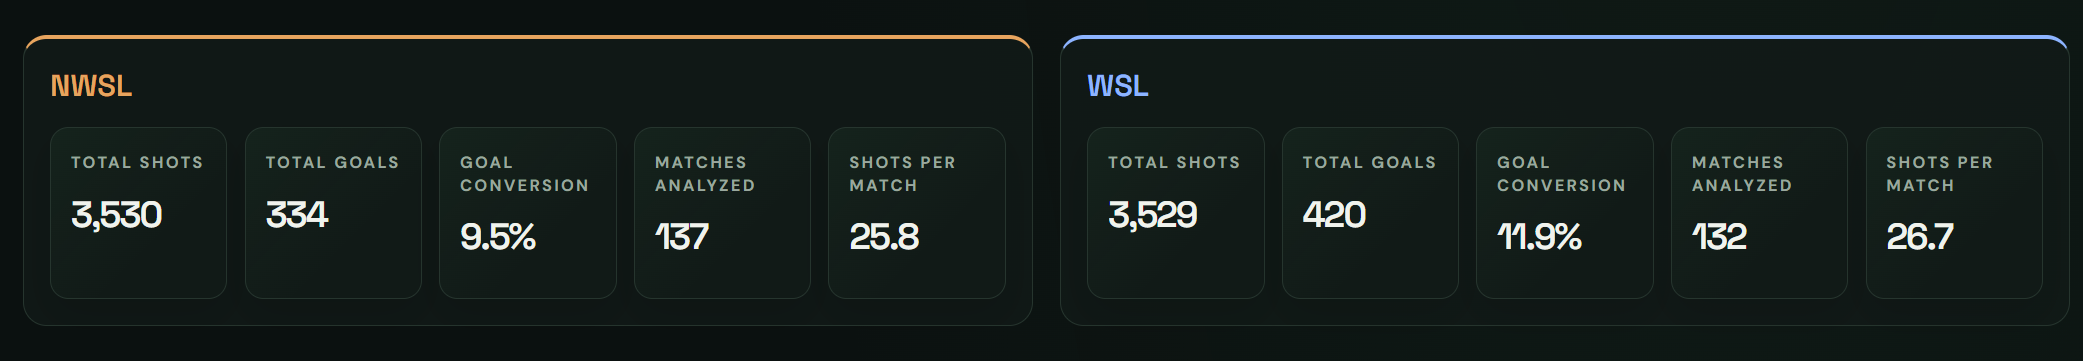

Because the number of shots differed by only one between the leagues, I was curious to learn how the WSL might different in play from the NWSL that could provide insights into their higher goal conversion rate. Did they take shots closer to the goal? Did they score more from breakaways or set-pieces?

### 2. Exploring Different Visualizations

My first approach to visualizing shot locations was plotting individual shots on a soccer field. With thousands of observations, however, it was difficult to interpret patterns due to many overlapping points. Ultimately, I decided that the heatmaps communicated the information most effectively and that having additional ways to visualize the same information added unnecessary complexity to the dashboard.


In [ ]:
# This is a condensed version of how I arranged the heatmaps in Dash.

html.Div(
    [
        dcc.Graph(
            figure=create_shot_map(
                league_shots["nwsl"],
                density_max=shared_density_max,
            )
        ),
        dcc.Graph(
            figure=create_shot_map(
                league_shots["wsl"],
                density_max=shared_density_max,
            )
        ),
    ],
    className="shot-map-grid",
)

The prior iteration of the heat map

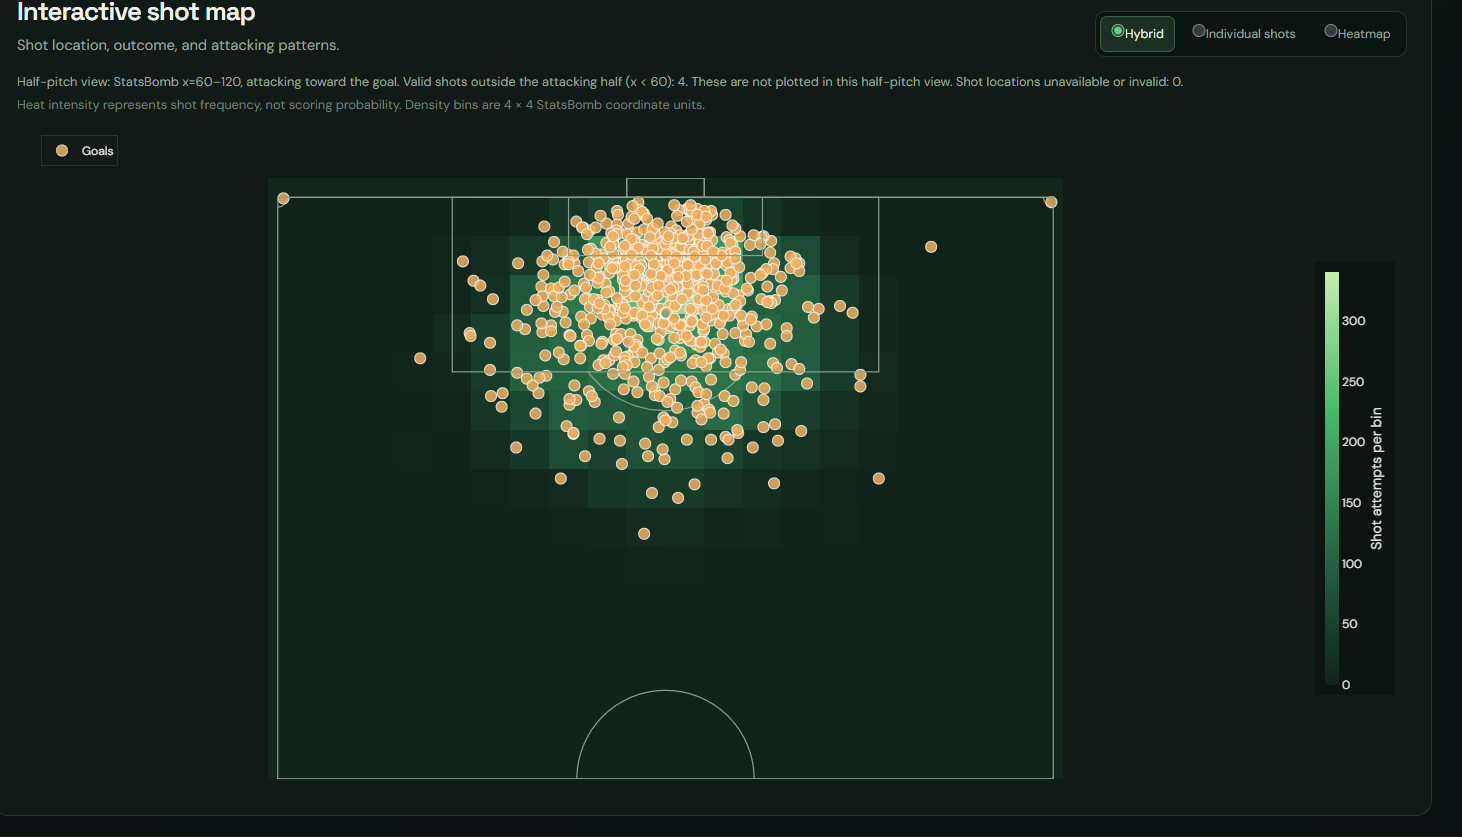

The final iteration of the heat map
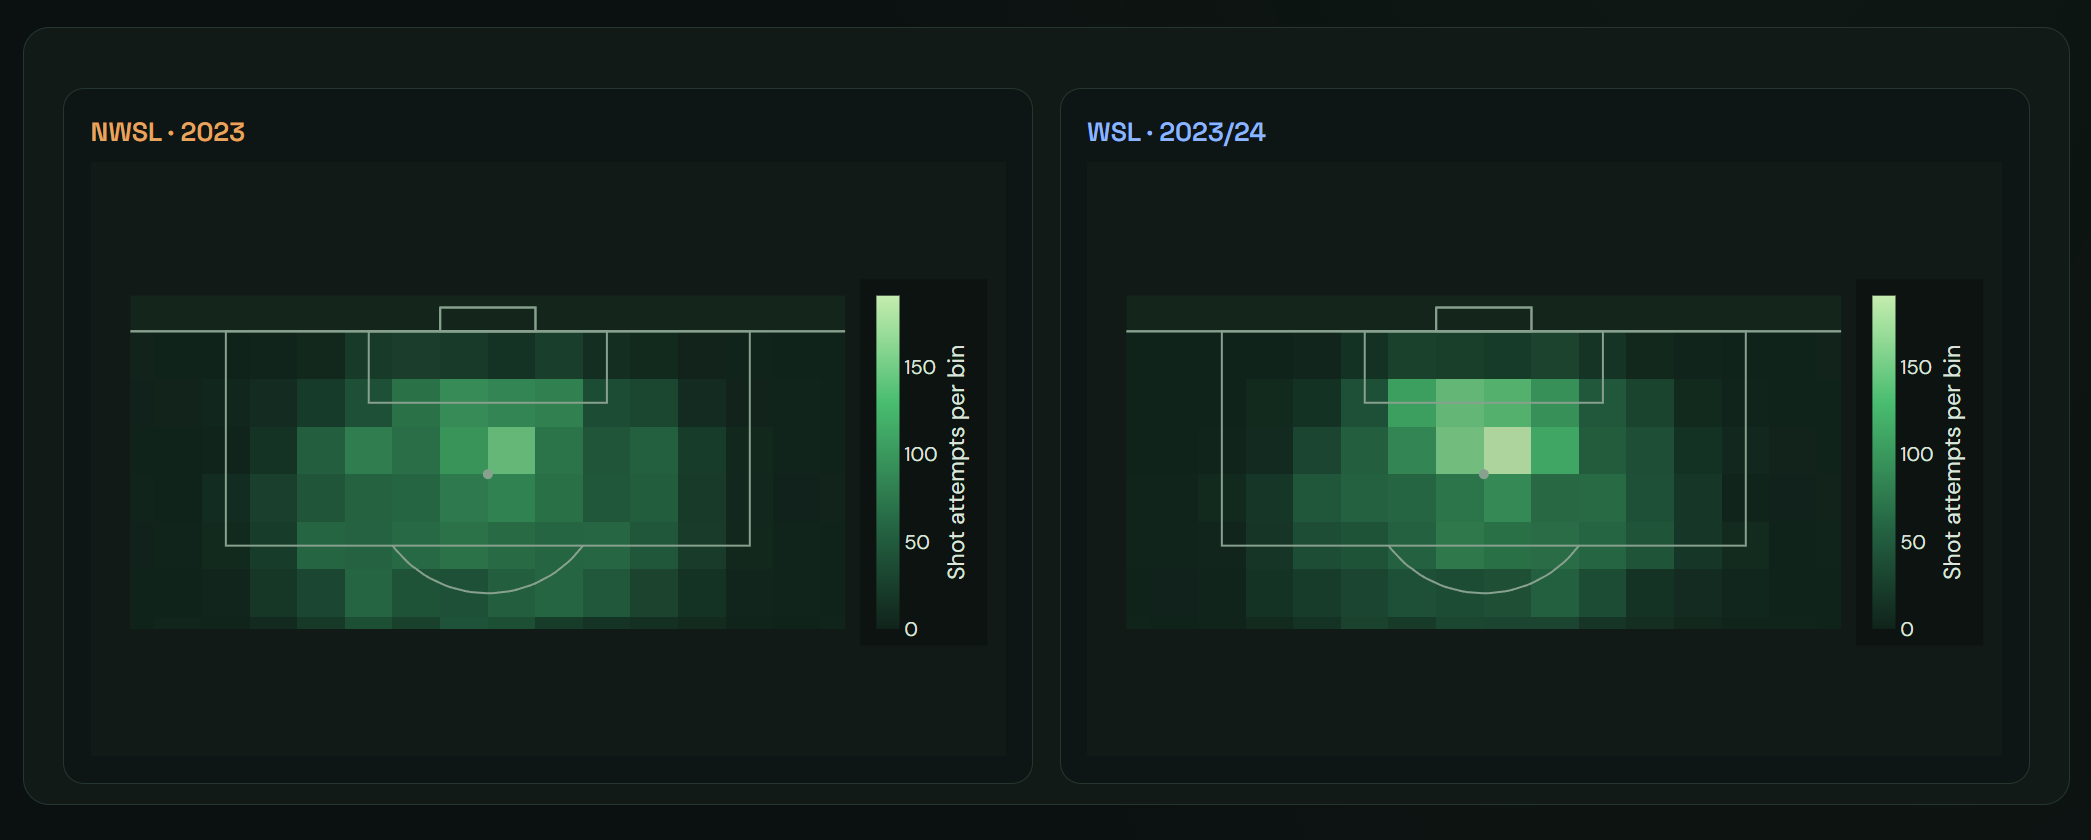

I also experimented with Sankey diagrams to explore the relationships between different shot characteristics. One consideration when creating a Sankey diagram is the order in which the variables are displayed, as this determines which relationships can be directly observed. I'll speak to this more later, but AI originally created the Sankey diagram with the categories organized in a way that didn't meaningfully contribute to identifying any patterns. Once I realized this, I changed the order and was able to uncover a few interesting tidbits.

### 3. Creating the Dashboard Layout

Once I had the individual visualizations, I used Dash to arrange them in the dashboard. I organized the dashboard into three sections: shot distribution, shot characteristics, and goal-scoring efficiency. Each section, as I outlined in a previous part of this notebook, tries to unearth a potential pattern based on learnings from previous visualizations.

To make comparing and contrasting the two leagues straightforward, I placed the heatmaps and Sankey diagrams side by side and used consistent colors and positioning to represent each league throughout the dashboard.

### 4. Adding Linked Interactivity

I wanted users to be able to explore both the types of shots players were taking and the types of shots they were scoring. To do this, I added a toggle that switches between "All shots" and "Goals only" and updates both Sankey diagrams at the same time.

The "All shots" view includes whether or not each shot resulted in a goal, which helps users visualize how many shots are unsuccessful. When switching to "Goals only," this last group is removed, making it easier to see the connections between shot location, play pattern, and body part for shots that resulted in goals. This highlights some small patterns, like how the WSL scores from more headers from set plays like corner kicks and free kicks: WSL scored 35 goals from corners and 16 from free kick whereas the NWSL scored 23 from corners and 6 from free kicks.


In [ ]:
# I used a Dash callback to update both Sankey diagrams and their observation counts 
# whenever the user switches between "All shots" and "Goals only.

@app.callback(
    Output("nwsl-sankey-graph", "figure"),
    Output("wsl-sankey-graph", "figure"),
    Output("nwsl-sankey-count", "children"),
    Output("wsl-sankey-count", "children"),
    Input("sankey-mode", "value"),
)
def update_sankey(mode):
    # Logic to update the diagrams
    ...

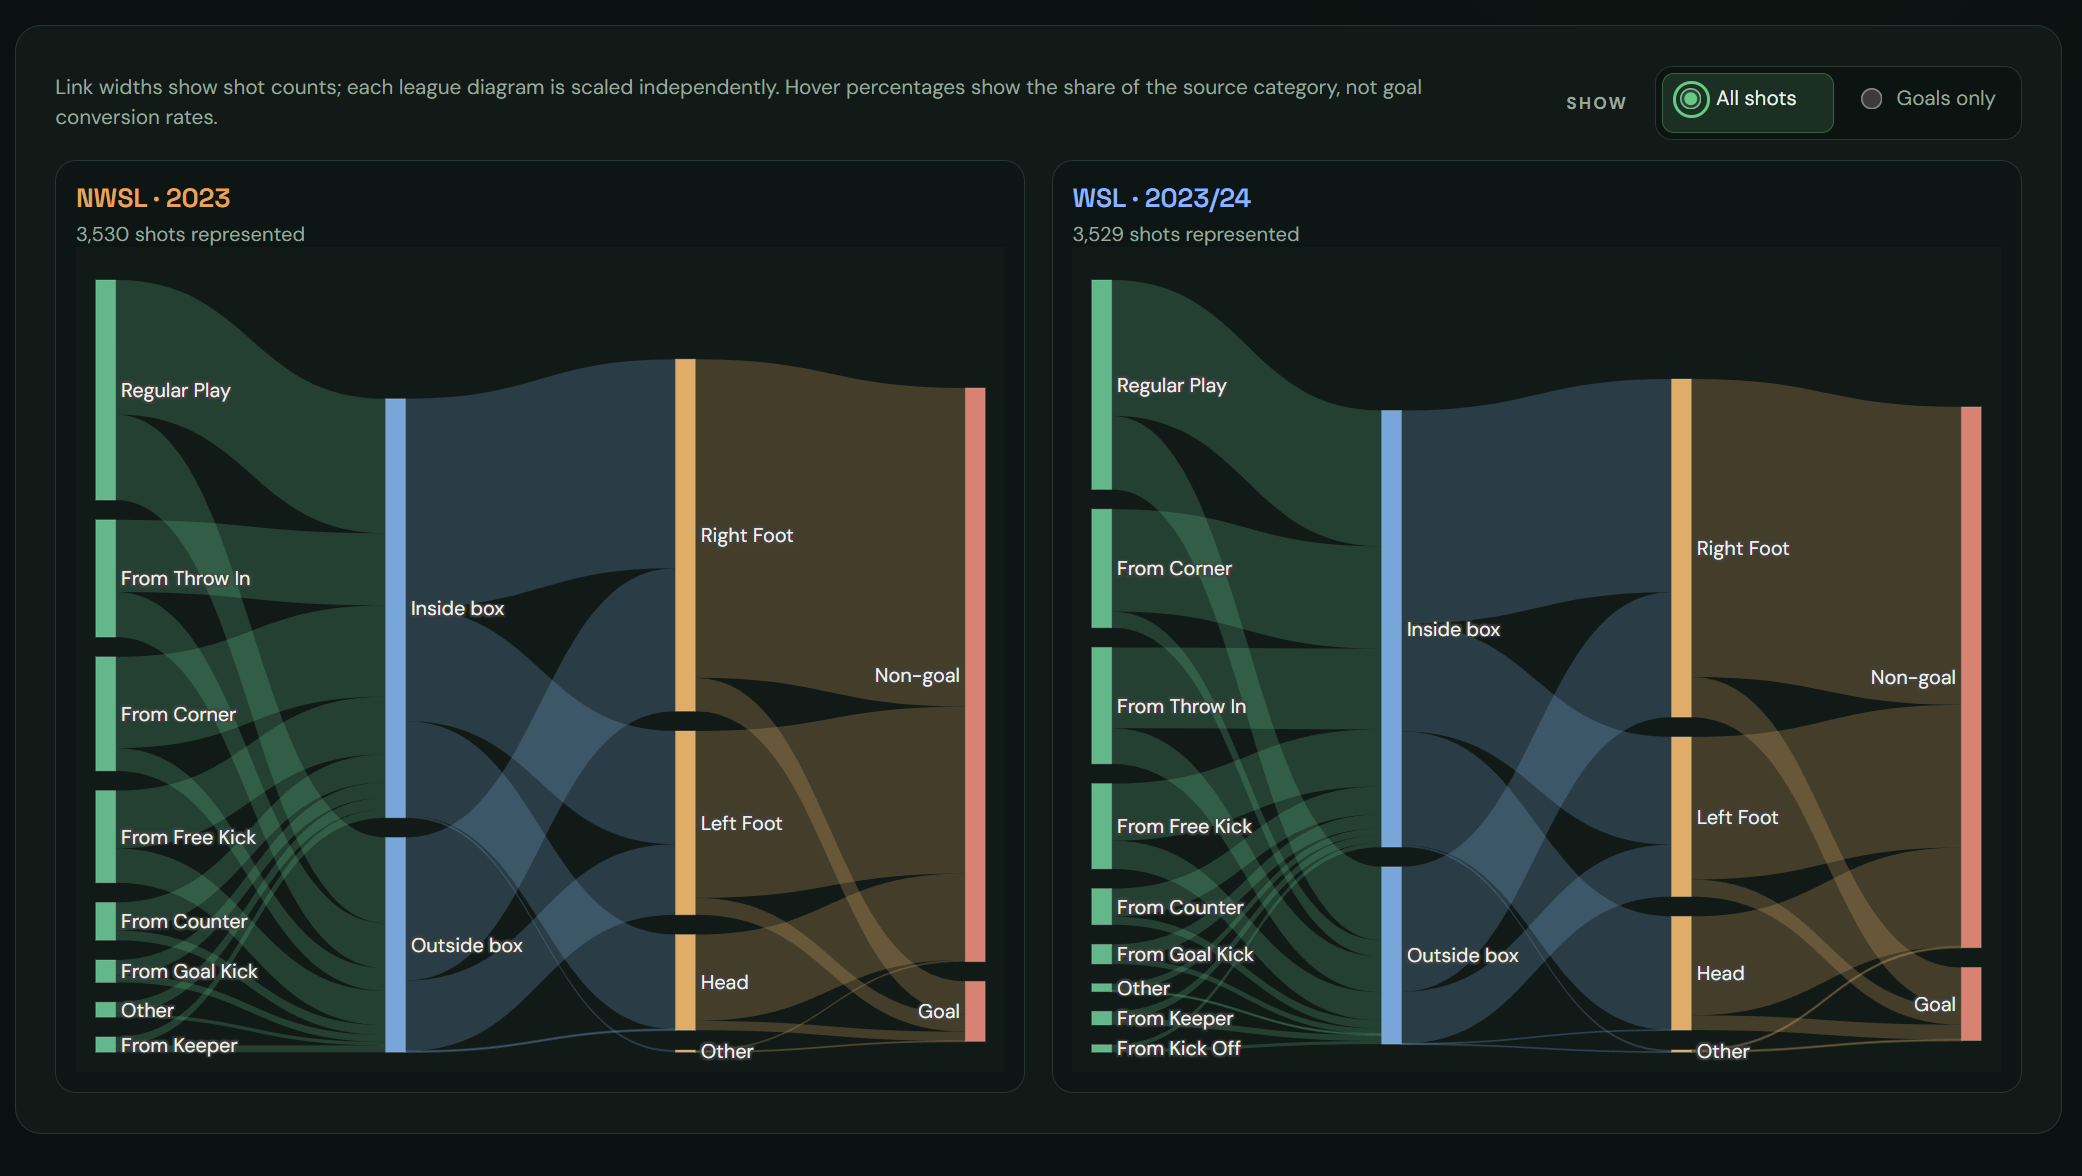

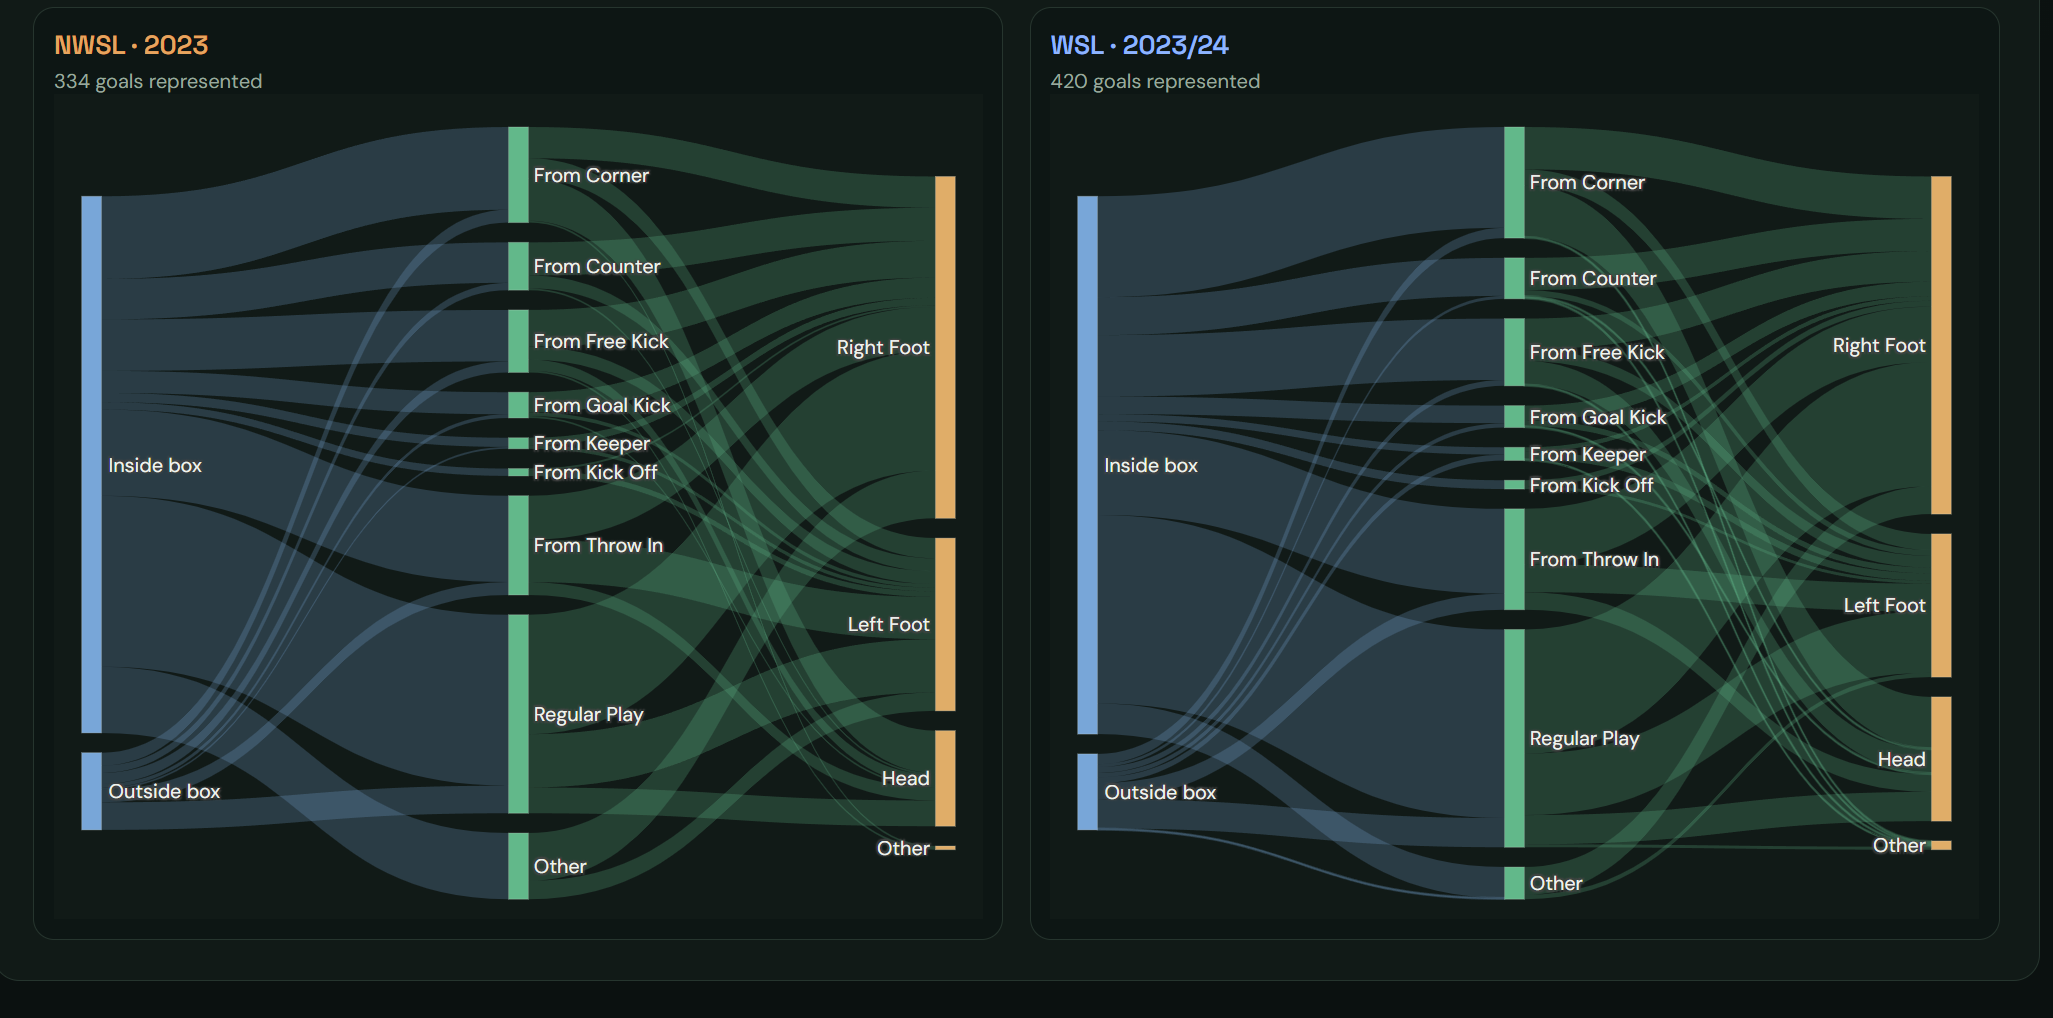

### 5. Findings From Exploration

One of my initial assumptions was that the WSL's higher goal conversion rate might be explained by differences in where teams took their shots, assuming that a higher conversion rate meant more shots at closer range. I actually started by plotting individual shots, but the data was so condensed that it was difficult to interpret. I then moved to using a heat map. The heat map shows that the WSL takes more shots at the 6 yard line and more centrally in the box, whereas the NWSL has more shots closer to the perimeter of the 18-yard box.

I then wondered about other things that could contribute to goal conversion, like type of play and type of shot. I had to create the right visualization for the right data to make patterns visible. At first, I tried a mirrored bar chart to compare play patterns, but because the play patterns were so similar, the graphic didn't add much to the dashboard. That's when I came up with the Sankey diagram instead.


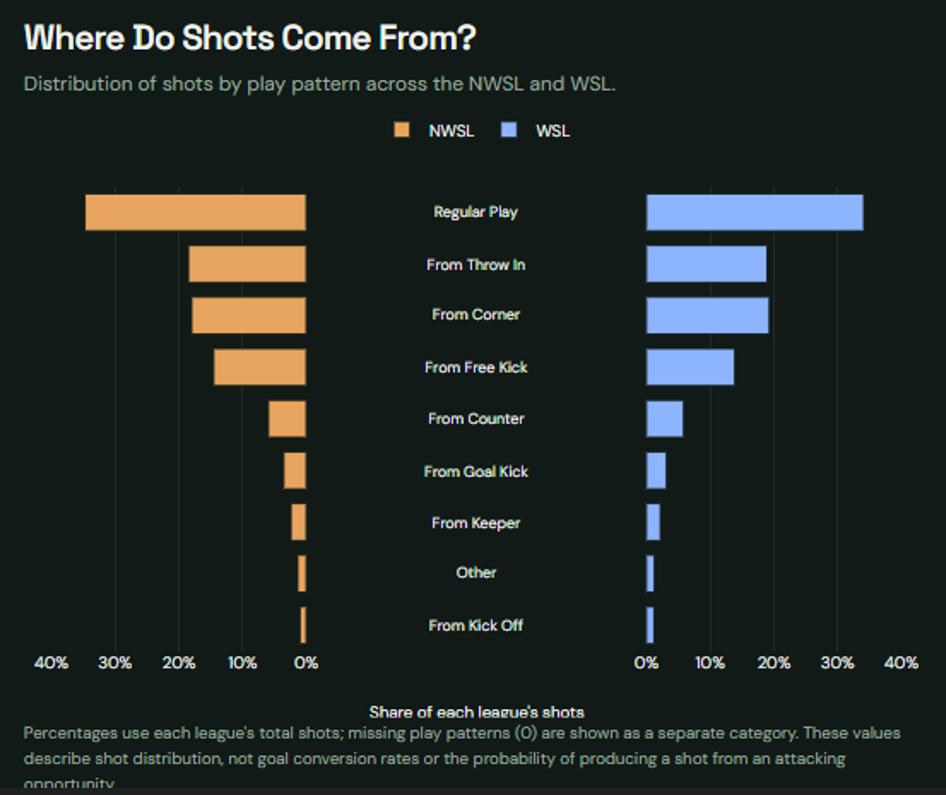

Even so, much of the data only surfaced small patterns. My last effort to find a meaningful pattern was to calculate how assists compare between the leagues to see if there was any pattern there.

While some small patterns arose in the data that indicate how the two leagues differ in their shot location, shot type, play pattern, and assist conversion, these findings suggest that the disparity in conversion rates can't easily be attributed to one particular shot characteristic. Additional exploration would be needed to better understand the factors contributing to these differences.

# AI Log and Troubleshooting

Entry 1: Scaling the dumbbell chart

Tool: GitHub Copilot

What I asked for / what I was trying to do: Create a visualization that made it easy to compare shot conversion rates by play pattern across the two leagues.

What came back / what happened: The dumbbell chart included all play patterns including "Other."

What was wrong or could be better: The conversion rates for "Other" were significantly higher than those of the other play patterns, causing the remaining data points to appear compressed. This was not ideal because "Other" was not an important characteristic to keep and was making the rest of the meaningful data difficult to see.

How I noticed: When reviewing the chart, it was difficult to distinguish the differences in conversion rates between the leagues.

What I did instead: I excluded "Other" from the dumbbell chart, which allowed me to use a smaller range on the x-axis and made the differences easier to see. I kept these observations in the underlying dataset and other visualizations.

Before

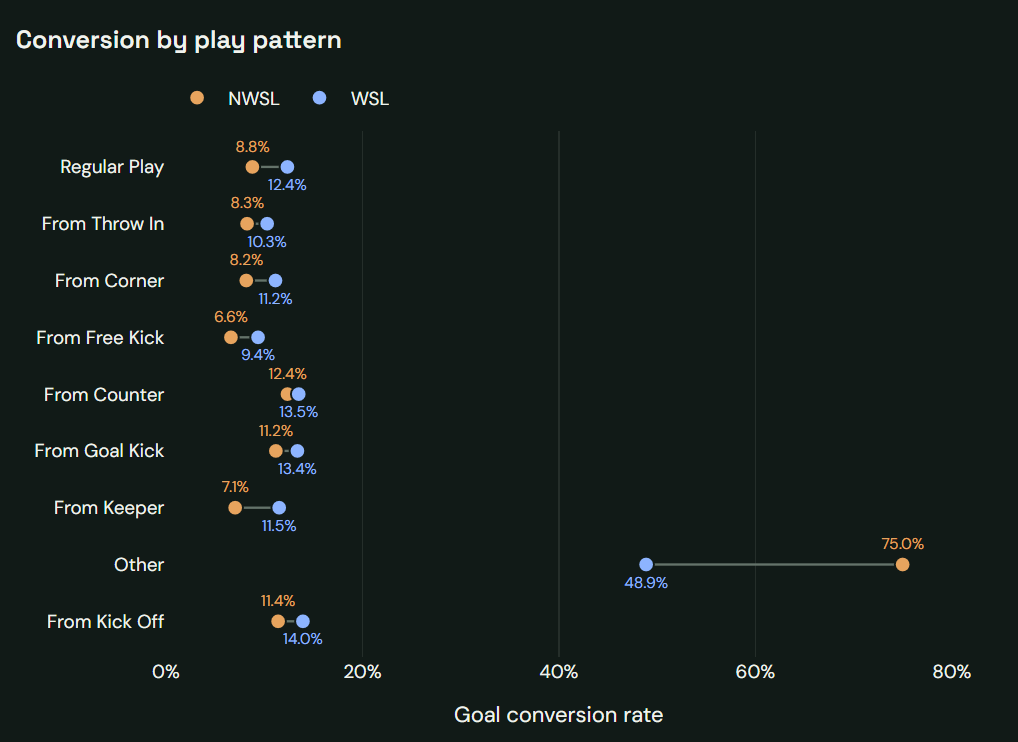

After

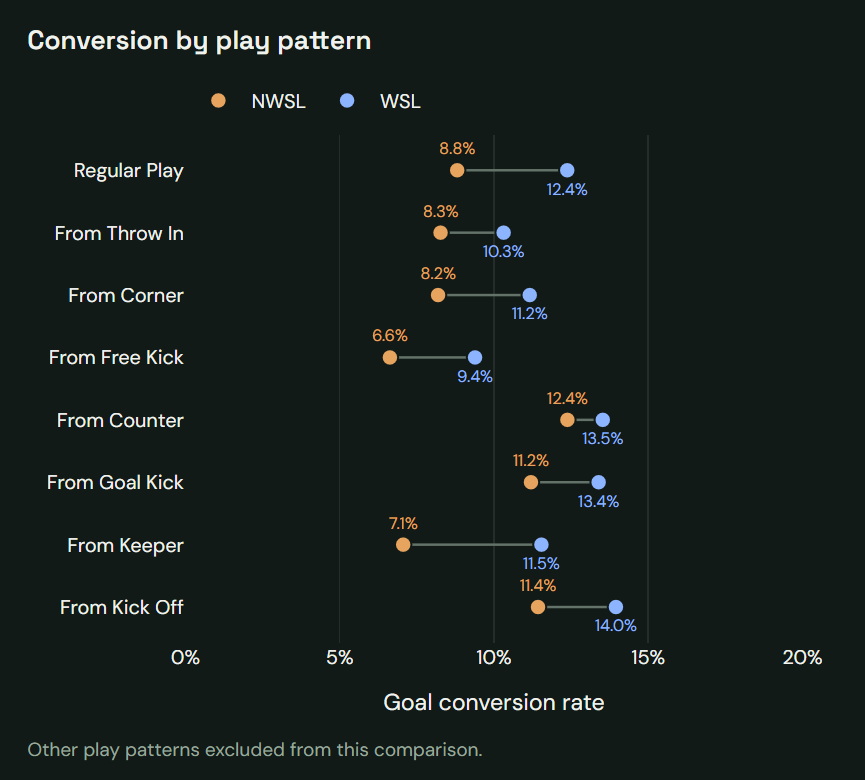

Entry 2: Arrangement of the Sankey diagram

Tool: GitHub Copilot

What I asked for / what I was trying to do: Create a visualization that showed relationships between different shot characteristics.

What came back / what happened: The original Sankey diagram displayed play pattern, shot location, body part, and outcome, in that order.

What was wrong or could be better: Having shot location between play pattern and body part made it difficult to understand the relationship between those two characteristics. (See the differences below)

How I noticed: While exploring the data, I wanted to see how many headers came from corners and free kicks but realized I couldn't easily determine this from the visualization.

What I did instead: I switched the order of shot location and play pattern so that I could directly explore the relationship between play pattern and body part.

Before
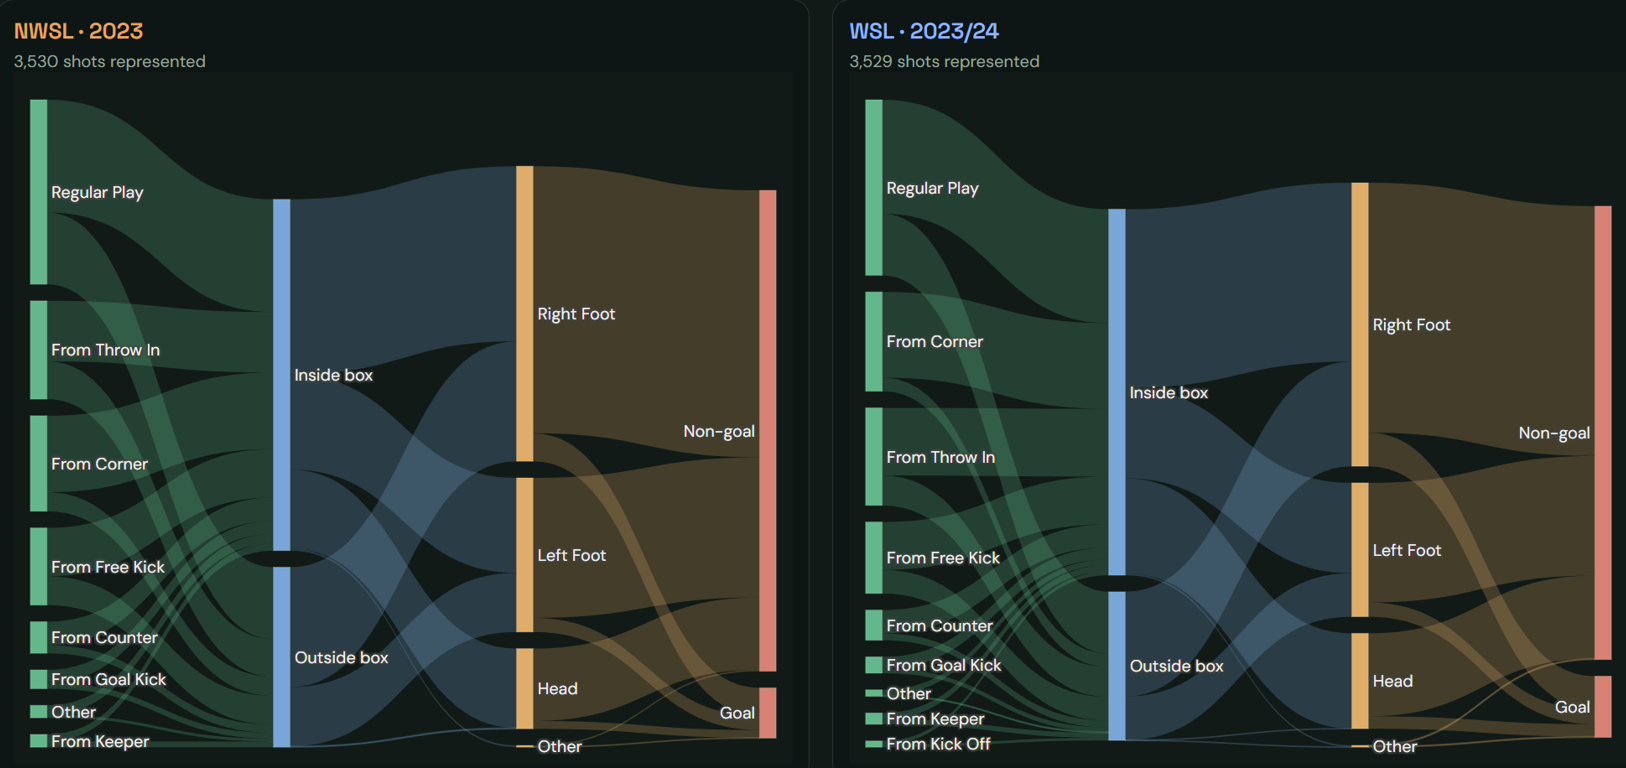

After
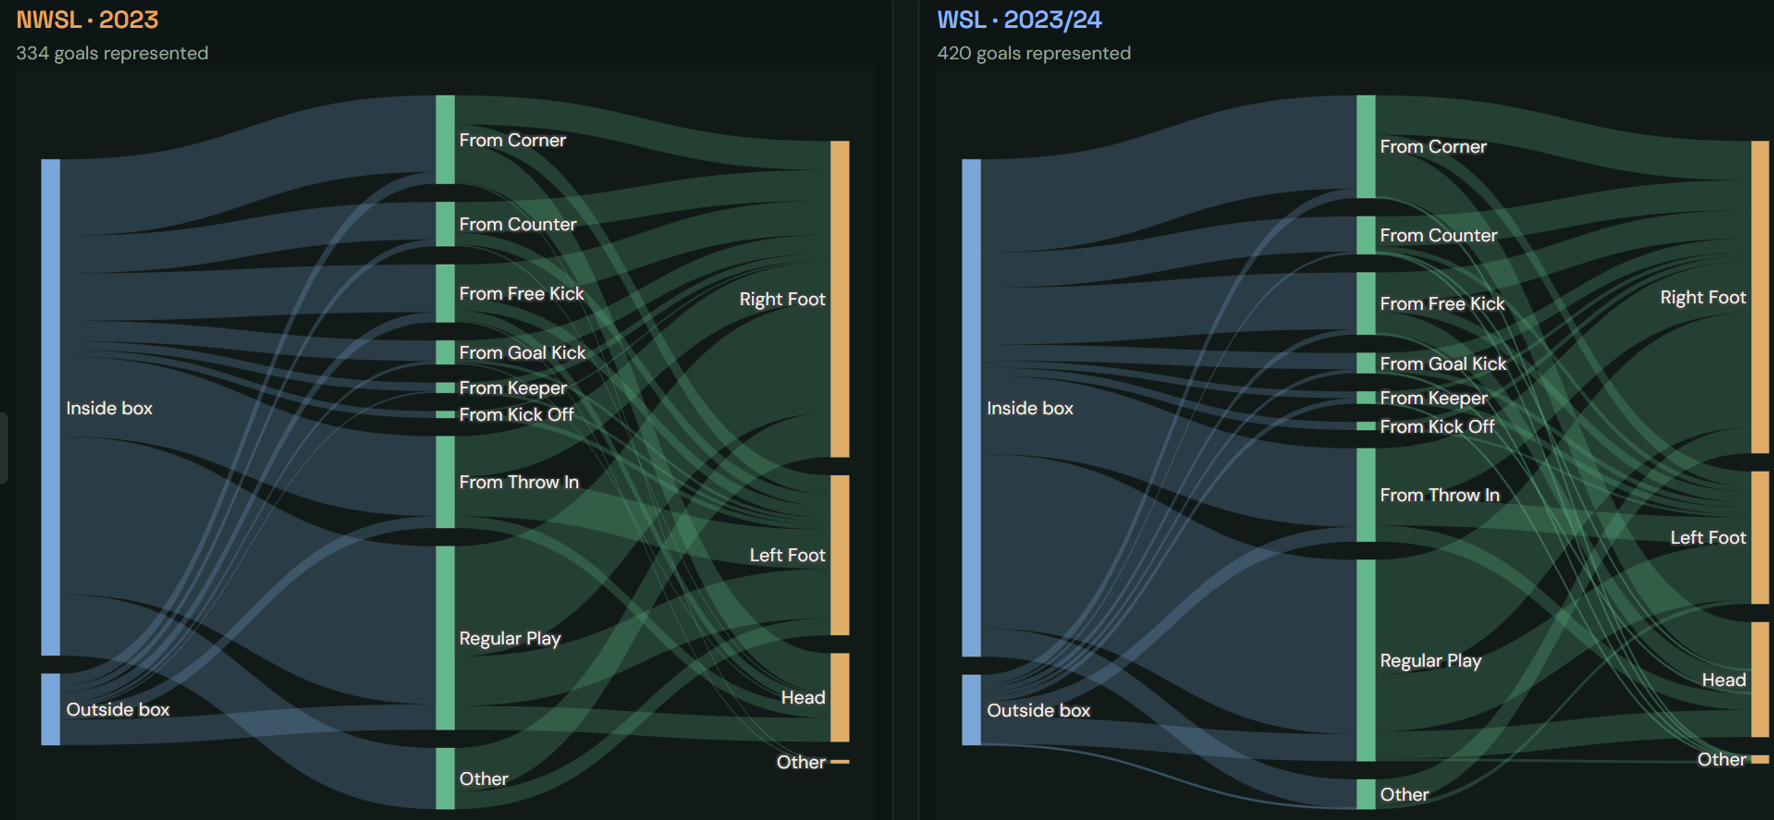

Entry 3: Sharing the dataset

Tool: ChatGPT

What I asked for / what I was trying to do: Determine how to make my dashboard publicly accessible.

What came back / what happened: ChatGPT initially recommended making the parquet file available in my GitHub repository.

What was wrong or could be better: StatsBomb's license prohibits redistribution of the underlying data.

How I noticed: I reviewed the license and discussed its restrictions with ChatGPT.

What I did instead: I kept the parquet file out of my GitHub repository and configured Render to retrieve the data and generate the parquet file when building the application. This led to me actually having to change the original configuration of my heat map which included individual shots. The individual shots surfaced data that was prohibited by the usage license, so I had to make it just a heat map. This also worked in the favor of the dashboard because the density of the shot data made it difficult to identify any patterns anyway.

# Deployment Instructions

I used Render to host my dashboard so that others could access and interact with it without having to install any software or download the data.

### Step 1: Prepare the GitHub repository

I developed my dashboard locally using VS Code and stored my code in a GitHub repository. Before deploying the dashboard, I needed to make sure that the repository included:

- The Python code used to create the dashboard.
- A `pyproject.toml` file that specifies the required Python libraries.
- A script that retrieves the StatsBomb data and generates the parquet file.
- A `.python-version` file that specifies the version of Python to use (3.12).

Because of StatsBomb's licensing restrictions, I did not include the parquet file in my GitHub repository.

### Step 2: Connect GitHub to Render

1. Create a free account at [render.com](https://render.com).
2. Connect your GitHub account to Render.
3. Create a new Web Service.
4. Select the GitHub repository that contains the dashboard.

### Step 3: Configure the Web Service

Render requires some additional information about how to build and run the application. I used the following settings:

| Setting | Value |
|---|---|
| Name | womens-soccer-analysis |
| Language | Python 3 |
| Branch | main |
| Instance Type | Free |

**Build Command**

`pip install . && python -m soccer_dashboard.build_data --expected-total 7059`

This command installs the required libraries, retrieves the data from StatsBomb, and generates the parquet file that the dashboard uses.

**Start Command**

`gunicorn "soccer_dashboard.app:create_server()" --bind 0.0.0.0:$PORT --workers 1 --threads 4`

This command uses Gunicorn to run the application on Render's server.

### Step 4: Deploy the dashboard

Once the settings are configured, select Deploy Web Service. Render will install the required libraries, retrieve the data, and start the application. The deployment logs can be used to monitor progress and troubleshoot any errors.

Once the deployment is successful, Render provides a public URL that can be used to access the dashboard.

### Step 5: Test and maintain the dashboard

I tested the dashboard on both my computer and phone to make sure it was accessible and that the interactivity worked as expected.

Render can also automatically redeploy the dashboard when changes are made to the main branch of the GitHub repository. This allowed me to continue making improvements after the dashboard was initially deployed.

One limitation of using Render's free tier is that the application may take a minute or longer to load if it has not been accessed recently.

**GitHub repository:** https://github.com/loaf14/womens-soccer-analysis

**Live dashboard:** https://womens-soccer-analysis.onrender.com/